# Energy yield with sub-bandgap reflector

Created on 2026-10-14.

This notebook recreates Figs. 3 and 5 in the Manuscript [1].

[1] K. Jäger, J. Mandal, B. P. Rand, F. Meggers, and C. Becker. "How do sub-bandgap reflectors affect the performance of photovoltaic modules?" arXiv: 2604.20757 (v2, 2026)

In [1]:
import tempfile
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import MaxNLocator
from pv_tandem.thermal import GetAM15Data, GetLocData, CalcEY

## Initialize EY class

In [2]:
# Initialize PV module dictionary
pv_dict = {
    # Geometrical parameters
    'module_height': 1.5,               # in m
    'module_width': 1.1,                # in m
    'module_length': 1.7,               # in m
    'module_spacing': 100,              # in m
    'module_tilt_deg': 34.5,            # optimal tilt for TMY 2024 data in Princeton
    'module_plane_azimuth_deg': 180,    # PV module is facing South
    'ground_steps': 101,                # steps in view factor model

    # Environmental parameter
    'albedo': 0.3,

    # Parameters for temperature models (Ross, Fuentes or SAPM, from pvlib)
    'fuentes_module_emissivity': 0.84,  # Default: 0.84, used in Fuentes model
    'noct': 45,                         # Used in Ross model     
    'sapm_module_mount': 0,             # Used in SAPM model
                                        # 0: glass/glass, open rack
                                        # 1: glass/glass, close roof
                                        # 2: glass/polymer, open rack
                                        # 3: glass/polymer, insulated back

    # Parameters for sub-bandgap reflector (SBR) and J_sc calculation
    'j_sc_STC_no_EQE': 39,              # Short circuit current density at STC when no EQE data is available
    'use_EQE': True,                    # Use EQE data from an input file
    'wl_j_sc_min_nm': 300,              # lower bound for J_sc calcuation when EQE data is available
    'wl_j_sc_max_ref_nm': 1200,         # upper bound for J_sc calcuation for reference case when EQE data is available
    'wl_SBR_cutoff_nm': 1150,           # cutoff wavelength for the SBR

    # Parameters for electrical one-diode model
    'PCE': 24.76,                       # Power conversion efficiency of PV module at STC in %
    'tc_P': -0.40,                      # Temperature coefficient for power in %/K
    'tc_j_sc': 0.03,                    # Temperature coefficient for short-circuit current density in %/K
    'tc_V_oc': -0.4,                    # Temperature coefficient for open-circuit voltage in %/K
    'R_shunt': 3000,                    # Shunt resistance
    'R_series': 1.5,                    # Series resistance
    'n': 1,                             # Diode ideality factor
    'j_0': 1e-12,                       # Dark current density

    # Thermal coating parameter
    'loss': 0                           # Loss of thermal coating
    }

# Some general configuration
config_dict = {'irrad_model': 'vf', # "vf" or "simple"
               'temp_model': 'SAPM', # "Ross", "Fuentes", or "SAPM"
               'spectral': True, # Data is spectral or not. Would fit better fit to location data?
               'calc_j_sc': True #True # J_sc calculated for each spectrum (instead of pv_frac)
              }          

# File paths:
DATA_DIR = '../data_thermal'
reflection_filepath = f'{DATA_DIR}/SEMSC_Subedi_ea_PERC_UVVisNIR_sim_2020_Fig5b_sim.csv'
EQE_filepath = f'{DATA_DIR}/SEMSC_Subedi_ea_PERC_UVVisNIR_sim_2020_Fig6_B_sim_enc.csv'
# The NSRDB spectral data are stored as a zip file to keep the repository small
loc_zip_filepath = f'{DATA_DIR}/princeton-2024-1223393-fixed_tilt_35_spectral.zip'

## Testing variation of cutoff wavelength
Fig. 3

In [3]:
wl_SBR_cutoff_array = np.linspace(1100,1200,11)
avg_Delta_T = np.zeros(11)
EY_ref = np.zeros(11)
EY_sbr = np.zeros(11)
j_sc_ref = np.zeros(11)
j_sc_sbr = np.zeros(11)

def irr_weighted(x, w):
    return (x * w).sum() / w.sum()

dT_ar = {}
EY_ref_ar = {}
EY_sbr_ar = {}
dEY = {}
mount_labels = ['open rack', 'close roof']

# Extract the csv file to a temporary folder, which is deleted automatically
# (including the extracted file) at the end of the with block
with tempfile.TemporaryDirectory() as tmp_dir:
    with zipfile.ZipFile(loc_zip_filepath) as zf:
        csv_name = next(n for n in zf.namelist() if n.endswith('.csv'))
        loc_filepath = zf.extract(csv_name, tmp_dir)

    for mount, mount_name in enumerate(['or','cr']):
        pv_dict['sapm_module_mount'] = mount # 0: open rack, 1: close roof
        for i,wl in enumerate(wl_SBR_cutoff_array):
            print(f'Mount: {mount_labels[mount]}, SBR cutoff wl: {wl} nm', end = "\r")
            pv_dict['wl_SBR_cutoff_nm'] = wl
            am15_data = GetAM15Data(pv_reflection_filepath = reflection_filepath,
                                    pv_eqe_filepath = EQE_filepath,
                                    wl_jsc_max_ref_nm=pv_dict['wl_j_sc_max_ref_nm'], #
                                    wl_sbr_cutoff_nm=pv_dict['wl_SBR_cutoff_nm'] #lambda_cutoff
                                   )
            loc_data = GetLocData(nsrdb_data_filepath = loc_filepath,
                                  pv_reflection_filepath = reflection_filepath,
                                  pv_eqe_filepath = EQE_filepath,
                                  spectral_boolean = True,
                                  wl_jsc_max_ref_nm = pv_dict['wl_j_sc_max_ref_nm'], #
                                  wl_sbr_cutoff_nm = pv_dict['wl_SBR_cutoff_nm'] #lambda_cutoff
                                 )         
            ey_test = CalcEY(am15_data_obj = am15_data,
                             loc_data_obj = loc_data,
                             pv_dict = pv_dict,
                             config_dict = config_dict
                            )
        
            ey_test.get_ey()
        
            t_ref = ey_test.res['cell_temp_day_ref']
            t_sbr = ey_test.res['cell_temp_day_sbr']
            dT = t_ref - t_sbr
            irr = ey_test.res['irrad_poa']
            avg_Delta_T[i] = irr_weighted(dT,irr)     
        
            EY_ref[i] = ey_test.res['ey_ref']
            EY_sbr[i] = ey_test.res['ey_sbr']
            j_sc_ref[i] = am15_data.data['j_sc_am15_ref']
            j_sc_sbr[i] = am15_data.data['j_sc_am15_sbr']
    
        dT_ar[mount_name] = avg_Delta_T.copy()
        EY_ref_ar[mount_name] = EY_ref.copy()
        EY_sbr_ar[mount_name] = EY_sbr.copy()
        dEY[mount_name] = (EY_sbr.copy()-EY_ref.copy())/EY_ref.copy()

Mount: close roof, SBR cutoff wl: 1200.0 nm

In [4]:
"""
Two-panel figure for the beginning of the Results section.

Panel (a): J_sc(EQE) and mean Delta T vs. SBR cutoff wavelength (Princeton,
           open-rack and close-roof), illustrating the current-vs-cooling trade-off.
Panel (b): Delta AEY_rel vs. cutoff wavelength for open-rack and close-roof
           mounting (Princeton), with EY_ref/EY_sbr annotated.

"""

wl_cutoff = wl_SBR_cutoff_array.copy()

# Panel (a): mechanism
j_sc_eqe = j_sc_sbr          # array, J_sc(AM1.5) from EQE integration [mA/cm^2]
dT_open  = dT_ar['or']          # array, mean Delta T open-rack [degC]
dT_close = dT_ar['cr']          # array, mean Delta T close-roof [degC] (optional)

# Panel (b): result
ey_ref_open   = EY_ref_ar['or'] [0]  # scalar, EY_ref open-rack [kWh/m^2] (cutoff-independent)
ey_ref_close  = EY_ref_ar['cr'] [0]  # scalar, EY_ref close-roof [kWh/m^2] (cutoff-independent)
dAEY_open     = dEY['or']            # array, Delta AEY_rel open-rack [%]
dAEY_close    = dEY['cr']            # array, Delta AEY_rel close-roof [%]
ey_sbr_open   = EY_sbr_ar['or']      # array, EY_sbr open-rack [kWh/m^2] (for annotation)
ey_sbr_close  = EY_sbr_ar['cr']      # array, EY_sbr close-roof [kWh/m^2] (for annotation)

wl_headline = 1150.0                 # headline cutoff to mark on both panels
# -----------------------------------------------------------------------

if any(v is None for v in [j_sc_eqe, dT_open, ey_ref_open, ey_ref_close,
                            dAEY_open, dAEY_close, ey_sbr_open, ey_sbr_close]):
    raise ValueError("Fill in the PLACEHOLDER arrays with your sweep data before plotting.")

# colours: keep one colour per physical quantity across the whole figure
C_JSC   = 'darkgoldenrod'
C_DT_OR = 'royalblue'
C_DT_CR = 'indianred'
C_DT_LB = 'rebeccapurple' # label
C_OR    = 'royalblue'   # open-rack (dAEY curve)
C_CR    = 'indianred'   # close-roof (dAEY curve)

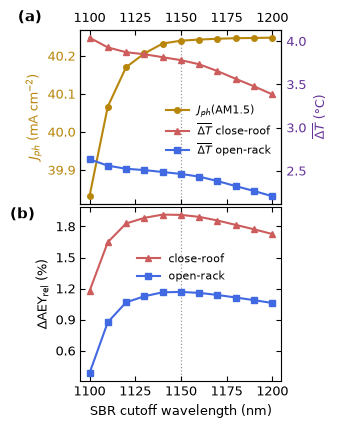

In [5]:
# Plot the figure
plt.rcParams['font.size'] = 9.0
plt.rcParams['font.family'] = 'sans-serif'
fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(8.8 / 2.54, 10.5 / 2.54))

# ============================== Panel (a) ================================
ax_a2 = ax_a.twinx()

l1, = ax_a.plot(wl_cutoff, j_sc_eqe, '-o', color=C_JSC, ms=4,
                label=r'$J_{ph}$(AM1.5)')
l2, = ax_a2.plot(wl_cutoff, dT_close, '-^', color=C_DT_CR, ms=4,
                label=r'$\overline{\Delta T}$ close-roof')
l3, = ax_a2.plot(wl_cutoff, dT_open, '-s', color=C_DT_OR, ms=4,
                label=r'$\overline{\Delta T}$ open-rack')

handles = [l1, l2, l3]

# panel (a): no x label; ticks on bottom (no numbers), ticks + numbers on top
ax_a.tick_params(axis='x', which='both', direction='in', top=True, bottom=True,
                 labeltop=True, labelbottom=False)
ax_a.set_ylabel(r'$J_{ph}$ (mA cm$^{-2}$)', color=C_JSC)
ax_a2.set_ylabel(r'$\overline{\Delta T}$ (°C)', color=C_DT_LB)
ax_a.tick_params(axis='y', labelcolor=C_JSC)
ax_a2.tick_params(axis='y', labelcolor=C_DT_LB)
ax_a.axvline(wl_headline, color='0.6', lw=0.9, ls=':', zorder=0)
ax_a.legend(handles, [h.get_label() for h in handles], frameon=False,
           fontsize=8, loc='center right', bbox_to_anchor=(1.0, 0.42))
tick_offset = plt.rcParams['xtick.major.pad']  # 7 pt by default
ax_a.annotate('(a)', xy=(0, 1), xycoords='axes fraction',
              xytext=(-45, tick_offset), textcoords='offset points',
              fontsize=11, fontweight='bold', va='bottom', ha='left')

# ============================== Panel (b) ================================
ax_b.plot(wl_cutoff, dAEY_close*100, '-^', color=C_CR, ms=4, label='close-roof')
ax_b.plot(wl_cutoff, dAEY_open*100, '-s', color=C_OR, ms=4, label='open-rack')
ax_b.axvline(wl_headline, color='0.6', lw=0.9, ls=':', zorder=0)
ax_b.tick_params(axis='x', which='both', direction='in', top=True, bottom=True)
ax_b.set_xlabel('SBR cutoff wavelength (nm)')
ax_b.set_ylabel(r'$\Delta$AEY$_\mathrm{rel}$ (%)')
ax_b.legend(frameon=False, fontsize=8, loc='center', bbox_to_anchor=(0.5, 0.65))
ax_b.text(-0.35, 1.0, '(b)', transform=ax_b.transAxes,
          fontsize=11, fontweight='bold', va='top', ha='left')
ax_b.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax_b.tick_params(axis='y', which='both', right=True)   # ticks on the right of (b), matching the twin axis of (a)

for ax in (ax_a, ax_a2, ax_b):
    ax.tick_params(axis='y', which='both', direction='in')

fig.tight_layout(pad = 0.2)

## Color plot for dependence on loss and temperature coefficient
Fig. 5

In [6]:
# Recreate classes with lambda_SBR = 1150 nm

pv_dict['wl_SBR_cutoff_nm'] = 1150

am15_data = GetAM15Data(pv_reflection_filepath = reflection_filepath,
                        pv_eqe_filepath = EQE_filepath,
                        wl_jsc_max_ref_nm=pv_dict['wl_j_sc_max_ref_nm'],
                        wl_sbr_cutoff_nm=pv_dict['wl_SBR_cutoff_nm'] #lambda_cutoff
                       )

# Extract the csv file to a temporary folder, which is deleted automatically
# (including the extracted file) at the end of the with block
with tempfile.TemporaryDirectory() as tmp_dir:
    with zipfile.ZipFile(loc_zip_filepath) as zf:
        csv_name = next(n for n in zf.namelist() if n.endswith('.csv'))
        loc_filepath = zf.extract(csv_name, tmp_dir)

        loc_data = GetLocData(nsrdb_data_filepath = loc_filepath,
                      pv_reflection_filepath = reflection_filepath,
                      pv_eqe_filepath = EQE_filepath,
                      spectral_boolean = True,
                      wl_jsc_max_ref_nm = pv_dict['wl_j_sc_max_ref_nm'],
                      wl_sbr_cutoff_nm = pv_dict['wl_SBR_cutoff_nm'] #lambda_cutoff
                     )
        
ey_test = CalcEY(am15_data_obj = am15_data,
                 loc_data_obj = loc_data,
                 pv_dict = pv_dict,
                 config_dict = config_dict
                )
        

In [7]:
# Initiate data arrays
tc_array = -np.linspace(0,0.5,26) # temperature coefficient
loss_array = np.linspace(0,.05,11)
gain_array = np.zeros([len(tc_array),len(loss_array)])

### Open-rack mount

In [8]:
# Calculate results for open-rack mount
pv_dict['sapm_module_mount'] = 0
for i,loss in enumerate(loss_array):
    for j, tc in enumerate(tc_array):  
        pv_dict['tc_P'] = tc
        pv_dict['loss'] = loss
        ey_test.get_ey_tc()
        ey_ref = ey_test.res['ey_tc_ref']
        ey_sbr = ey_test.res['ey_tc_sbr']
        gain_array[j,i] = (ey_sbr-ey_ref)/ey_ref

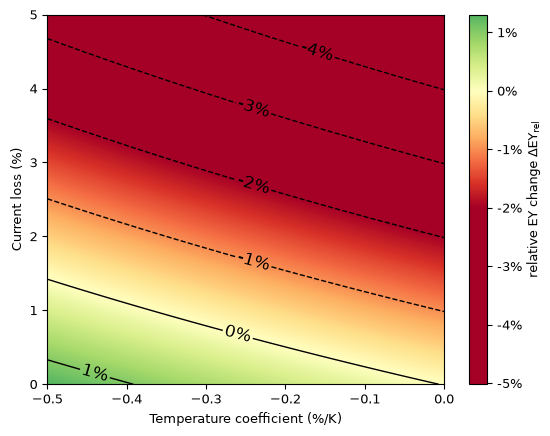

In [9]:
# Plot figure
plt.figure()
plt.contourf(tc_array,loss_array*100,gain_array.T*100,levels = 1000,cmap = cm.RdYlGn,vmin = -2, vmax = 2)
plt.colorbar(ticks = np.linspace(-5,2,8),format = '%d%%',label = "relative EY change $\Delta$EY$_\mathsf{rel}$")
c_set_w = plt.contour(tc_array,loss_array*100,gain_array.T*100,colors = 'k', linewidths = 1, levels = np.linspace(-5,2,8))
plt.clabel(c_set_w,fmt = '%d%%',inline_spacing=2,fontsize = 12)
plt.ylabel('Current loss (%)')
plt.xlabel('Temperature coefficient (%/K)')
plt.show()

### Close-roof mount

In [10]:
# Calculate results for close-roof mount
pv_dict['sapm_module_mount'] = 1
for i,loss in enumerate(loss_array):
    for j, tc in enumerate(tc_array):  
        pv_dict['tc_P'] = tc
        pv_dict['loss'] = loss
        ey_test.get_ey_tc()
        ey_ref = ey_test.res['ey_tc_ref']
        ey_sbr = ey_test.res['ey_tc_sbr']
        gain_array[j,i] = (ey_sbr-ey_ref)/ey_ref

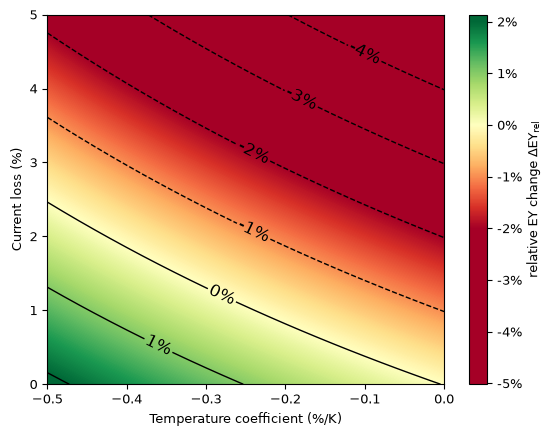

In [11]:
# Plot figure
plt.figure()
plt.contourf(tc_array,loss_array*100,gain_array.T*100,levels = 1000,cmap = cm.RdYlGn,vmin = -2, vmax = 2)
plt.colorbar(ticks = np.linspace(-5,2,8),format = '%d%%',label = "relative EY change $\Delta$EY$_\mathsf{rel}$")
c_set_w = plt.contour(tc_array,loss_array*100,gain_array.T*100,colors = 'k', linewidths = 1, levels = np.linspace(-5,2,8))
plt.clabel(c_set_w,fmt = '%d%%',inline_spacing=2,fontsize = 12)
plt.ylabel('Current loss (%)')
plt.xlabel('Temperature coefficient (%/K)')
plt.show()